<a href="https://colab.research.google.com/github/Kaifcse/forest-fire-weather-prediction/blob/main/algerian_forest_fire.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:

df = pd.read_csv("Algerian_forest_fires_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (247, 14)


,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
0,1,6,2012,29,57,18,0,65.7,3.4,7.6,1.3,3.4,0.5,not fire
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,not fire
4,5,6,2012,27,77,16,0,64.8,3,14.2,1.2,3.9,0.5,not fire


In [5]:

print("Dataset information:")
df.info()

print("\nColumn names:")
print(df.columns.tolist())

print("\nLast 10 rows:")
display(df.tail(10))

print("\nMissing values:")
print(df.isnull().sum())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 247 entries, 0 to 246
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   day          246 non-null    object
 1   month        245 non-null    object
 2   year         245 non-null    object
 3   Temperature  245 non-null    object
 4    RH          245 non-null    object
 5    Ws          245 non-null    object
 6   Rain         245 non-null    object
 7   FFMC         245 non-null    object
 8   DMC          245 non-null    object
 9   DC           245 non-null    object
 10  ISI          245 non-null    object
 11  BUI          245 non-null    object
 12  FWI          245 non-null    object
 13  Classes      244 non-null    object
dtypes: object(14)
memory usage: 27.1+ KB

Column names:
['day', 'month', 'year', 'Temperature', ' RH', ' Ws', 'Rain ', 'FFMC', 'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'Classes  ']

Last 10 rows:


,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
237,21,9,2012,35,34,17,0,92.2,23.6,97.3,13.8,29.4,21.6,fire
238,22,9,2012,33,64,13,0,88.9,26.1,106.3,7.1,32.4,13.7,fire
239,23,9,2012,35,56,14,0,89,29.4,115.6,7.5,36,15.2,fire
240,24,9,2012,26,49,6,2,61.3,11.9,28.1,0.6,11.9,0.4,not fire
241,25,9,2012,28,70,15,0,79.9,13.8,36.1,2.4,14.1,3,not fire
242,26,9,2012,30,65,14,0,85.4,16,44.5,4.5,16.9,6.5,fire
243,27,9,2012,28,87,15,4.4,41.1,6.5,8,0.1,6.2,0,not fire
244,28,9,2012,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,not fire
245,29,9,2012,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,not fire
246,30,9,2012,24,64,15,0.2,67.3,3.8,16.5,1.2,4.8,0.5,not fire



Missing values:
day            1
month          2
year           2
Temperature    2
 RH            2
 Ws            2
Rain           2
FFMC           2
DMC            2
DC             2
ISI            2
BUI            2
FWI            2
Classes        3
dtype: int64


In [6]:

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 15)

display(df.iloc[:8])
display(df.iloc[120:128])


,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
0,1,6,2012,29,57,18,0,65.7,3.4,7.6,1.3,3.4,0.5,not fire
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,not fire
4,5,6,2012,27,77,16,0,64.8,3,14.2,1.2,3.9,0.5,not fire
5,6,6,2012,31,67,14,0,82.6,5.8,22.2,3.1,7,2.5,fire
6,7,6,2012,33,54,13,0,88.2,9.9,30.5,6.4,10.9,7.2,fire
7,8,6,2012,30,73,15,0,86.6,12.1,38.3,5.6,13.5,7.1,fire


,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
120,29,9,2012,26,80,16,1.8,47.4,2.9,7.7,0.3,3,0.1,not fire
121,30,9,2012,25,78,14,1.4,45,1.9,7.5,0.2,2.4,0.1,not fire
122,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
123,Sidi-Bel Abbes Region Dataset,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
124,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
125,1,6,2012,32,71,12,0.7,57.1,2.5,8.2,0.6,2.8,0.2,not fire
126,2,6,2012,30,73,13,4,55.7,2.7,7.8,0.6,2.9,0.2,not fire
127,3,6,2012,29,80,14,2,48.7,2.2,7.6,0.3,2.6,0.1,not fire


In [7]:

df.columns = df.columns.str.strip()

print("Cleaned column names:")
print(df.columns.tolist())


Cleaned column names:
['day', 'month', 'year', 'Temperature', 'RH', 'Ws', 'Rain', 'FFMC', 'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'Classes']


In [8]:

# Assign region based on the original row index
df["Region"] = np.where(
    df.index < 122,
    "Bejaia",
    "Sidi-Bel-Abbes"
)

# Remove blank rows and rows containing headers or region titles
df = df[
    df["day"].notna() &
    (df["day"].astype(str).str.strip().str.lower() != "day") &
    (df["day"].astype(str).str.strip().str.lower() !=
     "sidi-bel abbes region dataset")
].copy()

# Reset the index
df.reset_index(drop=True, inplace=True)

print("Shape after cleaning structural rows:", df.shape)
print("\nRecords per region:")
print(df["Region"].value_counts())

display(df.head(3))
display(df.tail(3))


Shape after cleaning structural rows: (244, 15)

Records per region:
Region
Bejaia            122
Sidi-Bel-Abbes    122
Name: count, dtype: int64


,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,1,6,2012,29,57,18,0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,Bejaia
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire,Bejaia
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,Bejaia


,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
241,28,9,2012,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,not fire,Sidi-Bel-Abbes
242,29,9,2012,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,not fire,Sidi-Bel-Abbes
243,30,9,2012,24,64,15,0.2,67.3,3.8,16.5,1.2,4.8,0.5,not fire,Sidi-Bel-Abbes


In [9]:

numeric_cols = [
    "day", "month", "year", "Temperature", "RH", "Ws",
    "Rain", "FFMC", "DMC", "DC", "ISI", "BUI", "FWI"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Classes"] = df["Classes"].str.strip().str.lower()

print(df.dtypes)
print("\nMissing values after conversion:")
print(df.isnull().sum())


day              int64
month            int64
year             int64
Temperature      int64
RH               int64
Ws               int64
Rain           float64
FFMC           float64
DMC            float64
DC             float64
ISI            float64
BUI            float64
FWI            float64
Classes         object
Region          object
dtype: object

Missing values after conversion:
day            0
month          0
year           0
Temperature    0
RH             0
Ws             0
Rain           0
FFMC           0
DMC            0
DC             1
ISI            0
BUI            0
FWI            1
Classes        1
Region         0
dtype: int64


we are removing outliers and mising values



In [10]:

missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing[missing["Missing Count"] > 0])

print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


,Missing Count,Missing Percentage
DC,1,0.41
FWI,1,0.41
Classes,1,0.41


Total missing values: 3
Duplicate rows: 0


In [11]:

display(df[df.isnull().any(axis=1)])


,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
165,14,7,2012,37,37,18,0.2,88.9,12.9,NaN,12.5,10.4,NaN,NaN,Sidi-Bel-Abbes


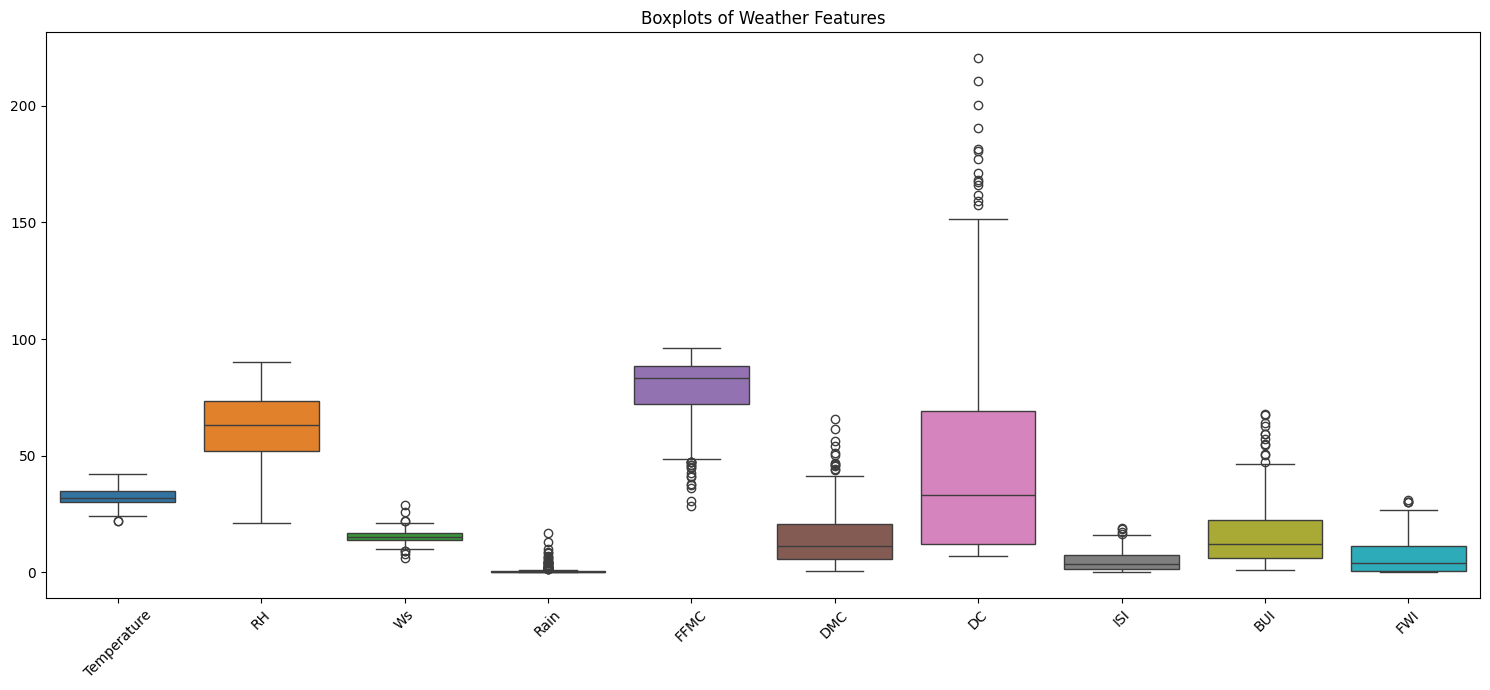

In [12]:

features = [
    "Temperature", "RH", "Ws", "Rain",
    "FFMC", "DMC", "DC", "ISI", "BUI", "FWI"
]

plt.figure(figsize=(15, 7))
sns.boxplot(data=df[features])
plt.title("Boxplots of Weather Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


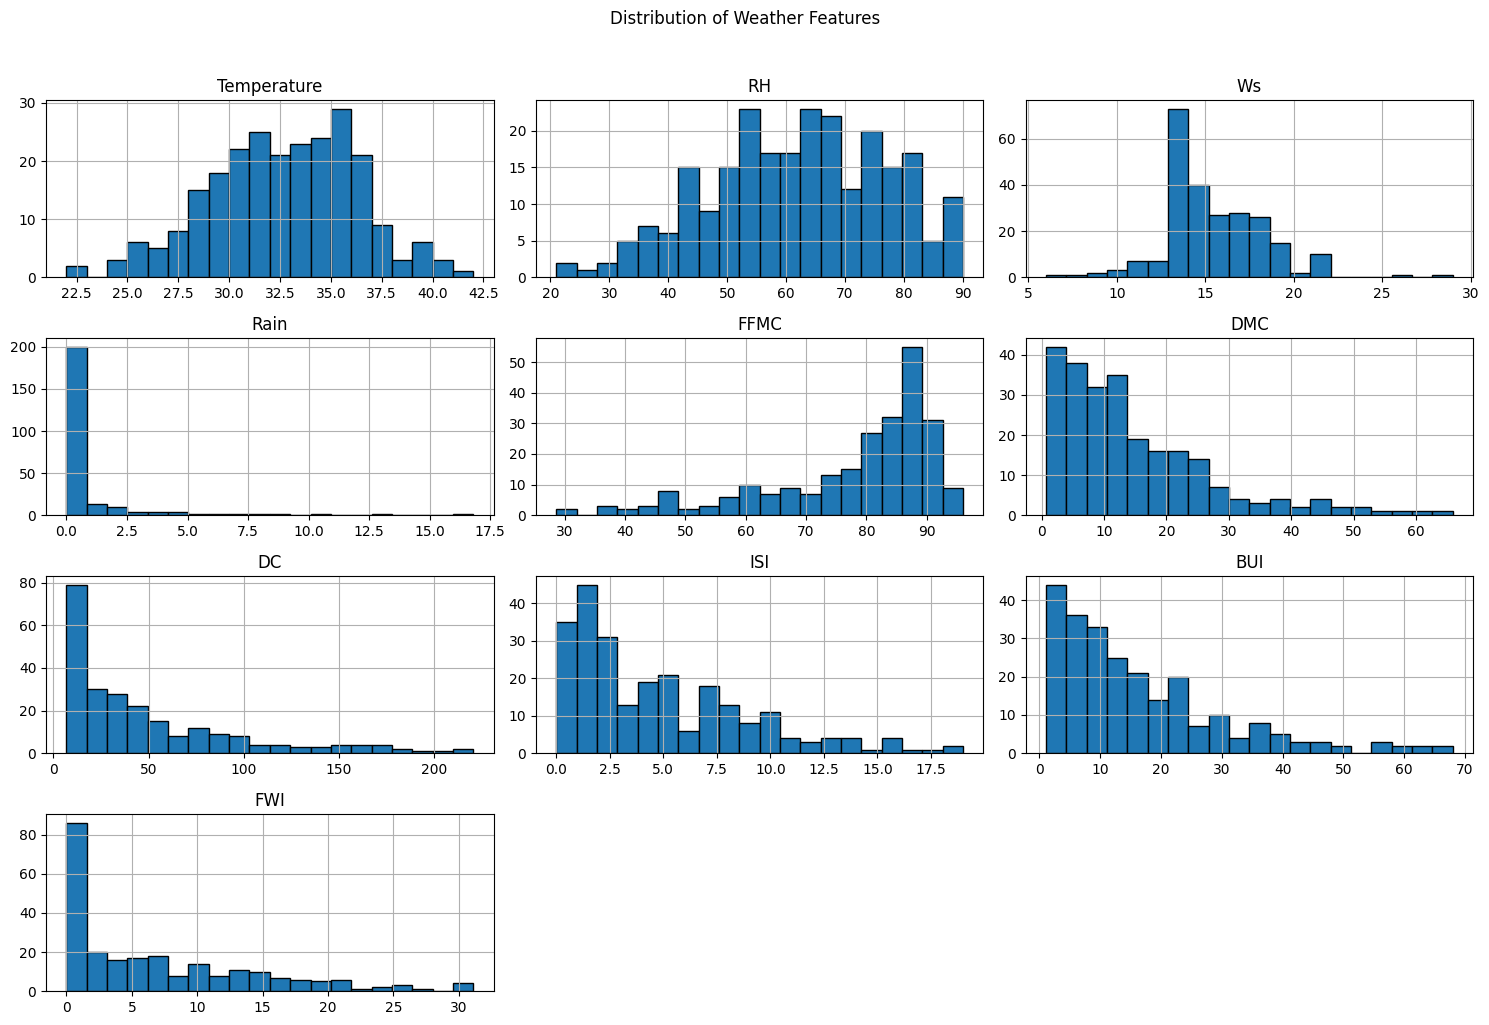

In [13]:

df[features].hist(
    figsize=(15, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Weather Features", y=1.02)
plt.tight_layout()
plt.show()


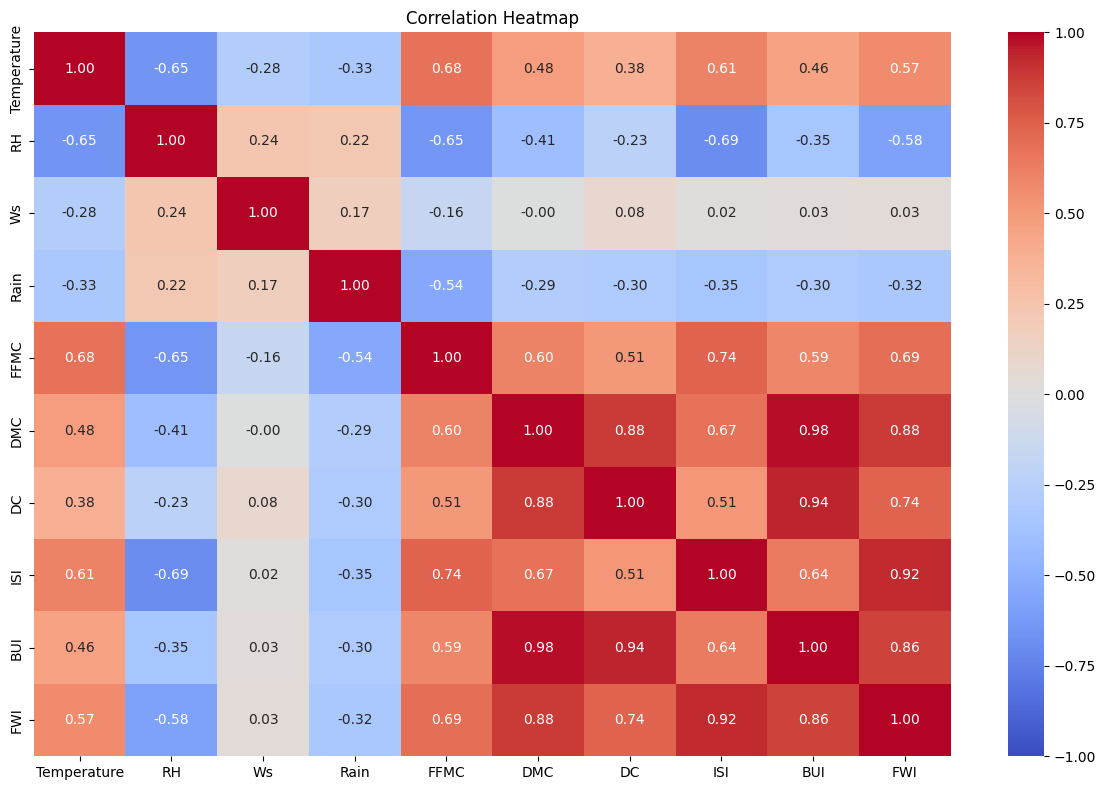

In [14]:

plt.figure(figsize=(12, 8))

corr = df[features].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


In [15]:

display(df[df.isnull().any(axis=1)])


,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
165,14,7,2012,37,37,18,0.2,88.9,12.9,NaN,12.5,10.4,NaN,NaN,Sidi-Bel-Abbes


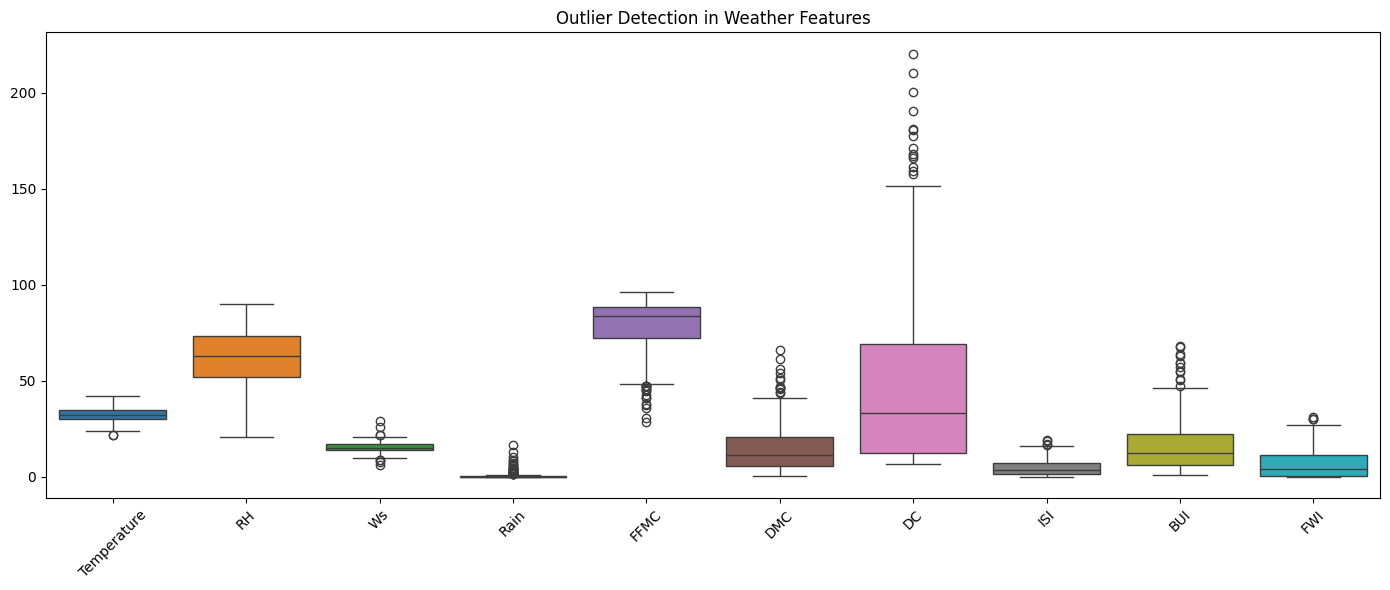

In [16]:

features = [
    "Temperature", "RH", "Ws", "Rain",
    "FFMC", "DMC", "DC", "ISI", "BUI", "FWI"
]

plt.figure(figsize=(14, 6))
sns.boxplot(data=df[features])
plt.xticks(rotation=45)
plt.title("Outlier Detection in Weather Features")
plt.tight_layout()
plt.show()


In [17]:

# Check the month and class columns
print("Months available:", sorted(df["month"].dropna().unique()))
print("\nClass labels:")
print(df["Classes"].value_counts(dropna=False))

# Create a month name column
month_names = {
    6: "June",
    7: "July",
    8: "August",
    9: "September"
}

df["Month_Name"] = df["month"].map(month_names)

display(df[["month", "Month_Name", "Classes", "Region"]].head())


Months available: [np.int64(6), np.int64(7), np.int64(8), np.int64(9)]

Class labels:
Classes
fire        137
not fire    106
NaN           1
Name: count, dtype: int64


,month,Month_Name,Classes,Region
0,6,June,not fire,Bejaia
1,6,June,not fire,Bejaia
2,6,June,not fire,Bejaia
3,6,June,not fire,Bejaia
4,6,June,not fire,Bejaia


In [18]:

monthly_counts = pd.crosstab(
    df["Month_Name"],
    df["Classes"]
)

month_order = ["June", "July", "August", "September"]
monthly_counts = monthly_counts.reindex(month_order)

display(monthly_counts)


Classes,fire,not fire
Month_Name,,
June,25,35
July,38,23
August,51,11
September,23,37


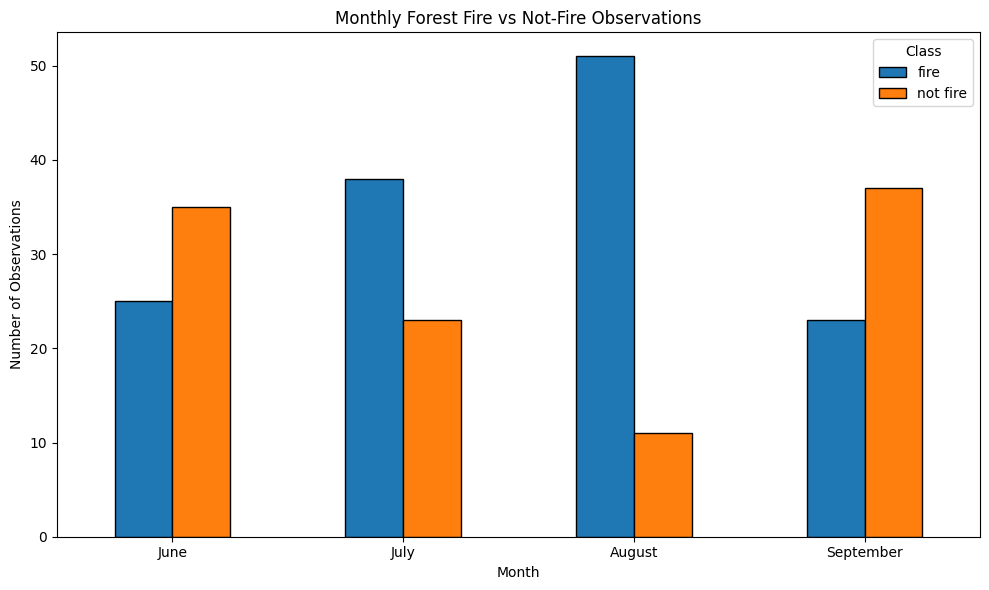

In [19]:

monthly_counts.plot(
    kind="bar",
    figsize=(10, 6),
    edgecolor="black"
)

plt.title("Monthly Forest Fire vs Not-Fire Observations")
plt.xlabel("Month")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.tight_layout()
plt.show()


In [20]:

monthly_summary = df.groupby("Month_Name").agg(
    Total_Observations=("Classes", "count"),
    Fire_Count=("Classes", lambda x: (x == "fire").sum()),
    Not_Fire_Count=("Classes", lambda x: (x == "not fire").sum())
)

monthly_summary["Fire_Percentage"] = (
    monthly_summary["Fire_Count"] /
    monthly_summary["Total_Observations"] * 100
).round(2)

monthly_summary = monthly_summary.reindex(month_order)

display(monthly_summary)


,Total_Observations,Fire_Count,Not_Fire_Count,Fire_Percentage
Month_Name,,,,
June,60,25,35,41.67
July,61,38,23,62.30
August,62,51,11,82.26
September,60,23,37,38.33


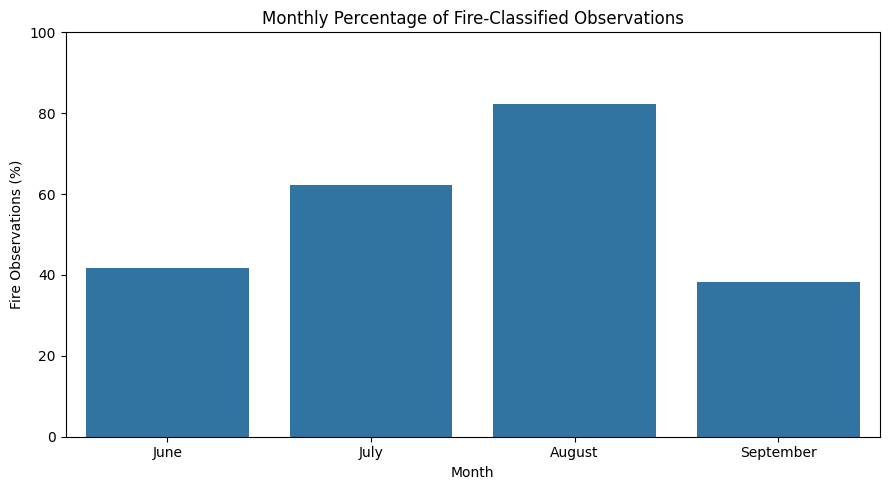

In [21]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=monthly_summary.reset_index(),
    x="Month_Name",
    y="Fire_Percentage"
)

plt.title("Monthly Percentage of Fire-Classified Observations")
plt.xlabel("Month")
plt.ylabel("Fire Observations (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


In [22]:

region_month = pd.crosstab(
    [df["Month_Name"], df["Region"]],
    df["Classes"]
).reindex(
    pd.MultiIndex.from_product(
        [month_order, df["Region"].dropna().unique()],
        names=["Month_Name", "Region"]
    ),
    fill_value=0
)

display(region_month)


Classes                    fire  not fire
Month_Name Region                        
June       Bejaia            13        17
           Sidi-Bel-Abbes    12        18
July       Bejaia            15        16
           Sidi-Bel-Abbes    23         7
August     Bejaia            24         7
           Sidi-Bel-Abbes    27         4
September  Bejaia             7        23
           Sidi-Bel-Abbes    16        14

In [23]:

region_monthly = (
    df[df["Classes"].notna()]
    .groupby(["Month_Name", "Region"])
    .agg(
        Total=("Classes", "count"),
        Fires=("Classes", lambda x: (x == "fire").sum())
    )
    .reset_index()
)

region_monthly["Fire_Percentage"] = (
    region_monthly["Fires"] / region_monthly["Total"] * 100
).round(2)

region_monthly["Month_Name"] = pd.Categorical(
    region_monthly["Month_Name"],
    categories=["June", "July", "August", "September"],
    ordered=True
)

region_monthly = region_monthly.sort_values(
    ["Month_Name", "Region"]
)

display(region_monthly)


,Month_Name,Region,Total,Fires,Fire_Percentage
4,June,Bejaia,30,13,43.33
5,June,Sidi-Bel-Abbes,30,12,40.00
2,July,Bejaia,31,15,48.39
3,July,Sidi-Bel-Abbes,30,23,76.67
0,August,Bejaia,31,24,77.42
1,August,Sidi-Bel-Abbes,31,27,87.10
6,September,Bejaia,30,7,23.33
7,September,Sidi-Bel-Abbes,30,16,53.33


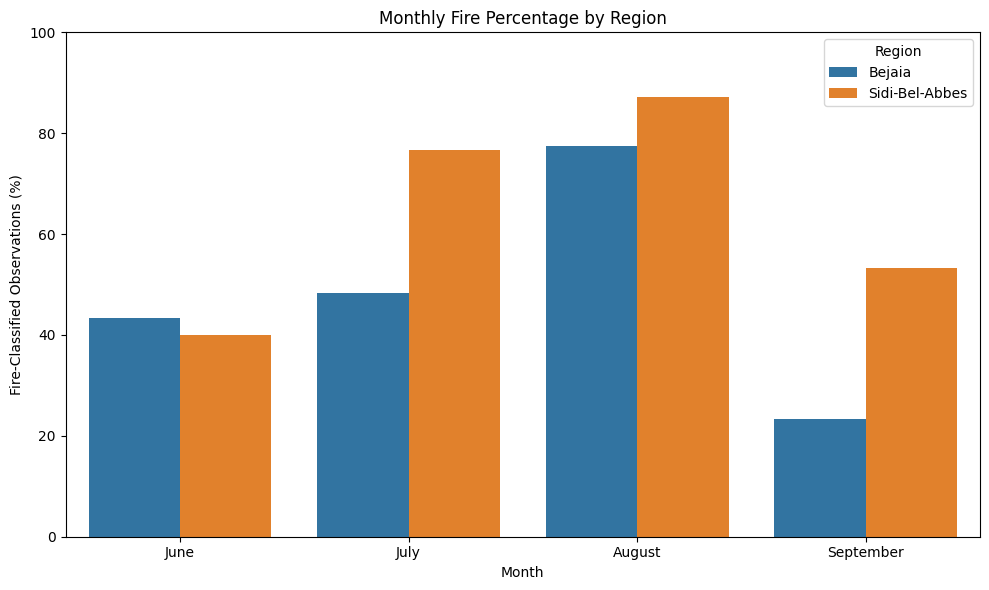

In [24]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=region_monthly,
    x="Month_Name",
    y="Fire_Percentage",
    hue="Region"
)

plt.title("Monthly Fire Percentage by Region")
plt.xlabel("Month")
plt.ylabel("Fire-Classified Observations (%)")
plt.ylim(0, 100)
plt.legend(title="Region")
plt.tight_layout()
plt.show()


feture slection process

In [25]:

# Keep rows with a known target
ml_df = df.dropna(subset=["Classes"]).copy()

# Normalize target labels
ml_df["Classes"] = ml_df["Classes"].str.strip().str.lower()

# Remove rows with unexpected target labels, if any
ml_df = ml_df[ml_df["Classes"].isin(["fire", "not fire"])].copy()

# Define target and candidate features
target = "Classes"

candidate_features = [
    "Temperature", "RH", "Ws", "Rain",
    "FFMC", "DMC", "DC", "ISI", "BUI"
]

X = ml_df[candidate_features]
y = ml_df[target].map({"not fire": 0, "fire": 1})

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(ml_df["Classes"].value_counts())


Feature matrix shape: (243, 9)
Target shape: (243,)

Target distribution:
Classes
fire        137
not fire    106
Name: count, dtype: int64


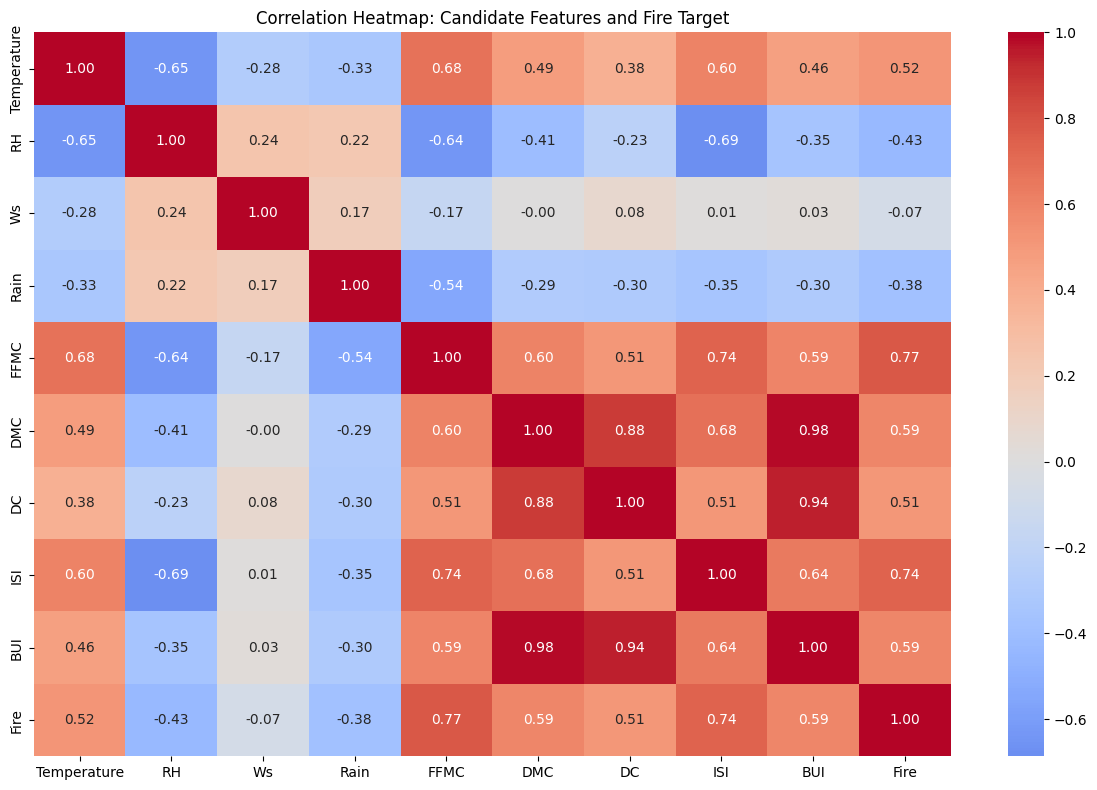

In [26]:

corr_df = X.copy()
corr_df["Fire"] = y

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_df.corr(),
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Heatmap: Candidate Features and Fire Target")
plt.tight_layout()
plt.show()


,Feature,Importance
4,FFMC,0.372756
7,ISI,0.348348
6,DC,0.091859
8,BUI,0.069723
5,DMC,0.061378
3,Rain,0.036206
1,RH,0.008426
0,Temperature,0.007280
2,Ws,0.004023


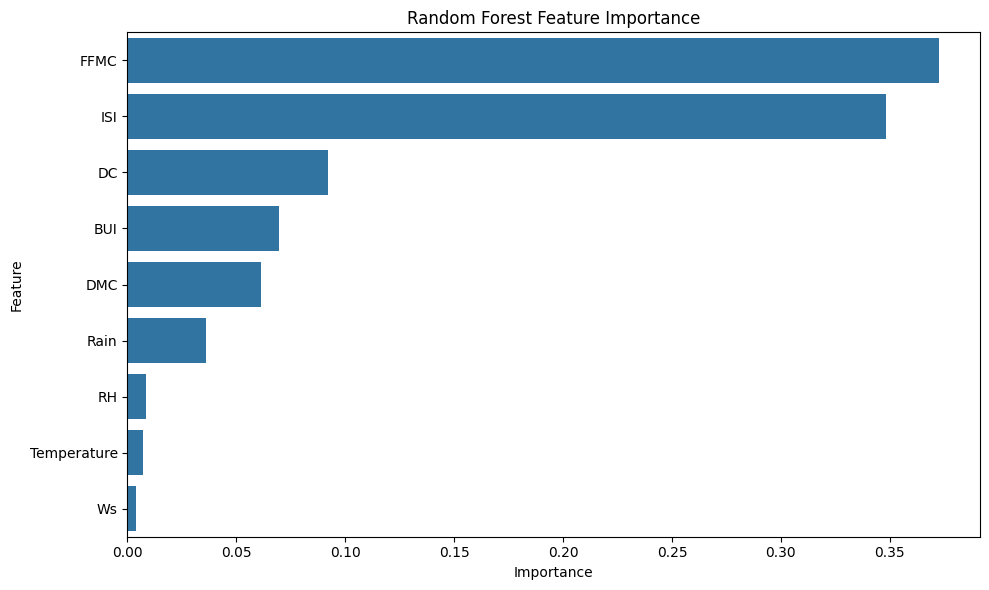

In [27]:

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

rf.fit(X, y)

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()


,Feature,Mutual_Information
7,ISI,0.644870
4,FFMC,0.636920
8,BUI,0.353364
5,DMC,0.335884
6,DC,0.305519
3,Rain,0.259309
0,Temperature,0.146101
1,RH,0.100182
2,Ws,0.032030


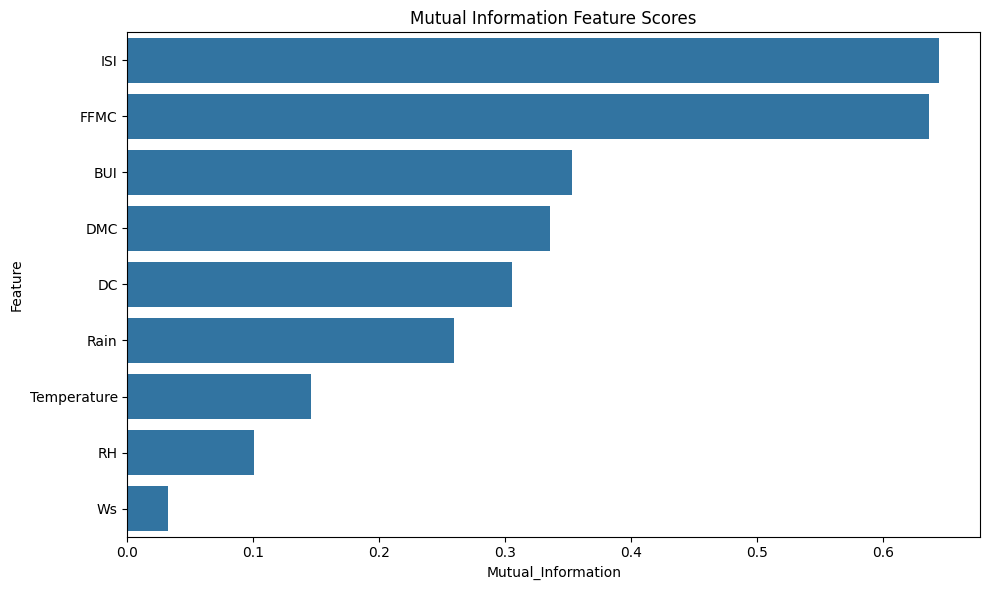

In [28]:

from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(
    X,
    y,
    random_state=42
)

mi_df = pd.DataFrame({
    "Feature": X.columns,
    "Mutual_Information": mi_scores
}).sort_values("Mutual_Information", ascending=False)

display(mi_df)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=mi_df,
    x="Mutual_Information",
    y="Feature"
)

plt.title("Mutual Information Feature Scores")
plt.tight_layout()
plt.show()


In [29]:

comparison = importance_df.merge(mi_df, on="Feature")

comparison["RF_Rank"] = comparison["Importance"].rank(
    ascending=False,
    method="min"
)

comparison["MI_Rank"] = comparison["Mutual_Information"].rank(
    ascending=False,
    method="min"
)

comparison = comparison.sort_values("RF_Rank")

display(comparison)


,Feature,Importance,Mutual_Information,RF_Rank,MI_Rank
0,FFMC,0.372756,0.636920,1.0,2.0
1,ISI,0.348348,0.644870,2.0,1.0
2,DC,0.091859,0.305519,3.0,5.0
3,BUI,0.069723,0.353364,4.0,3.0
4,DMC,0.061378,0.335884,5.0,4.0
5,Rain,0.036206,0.259309,6.0,6.0
6,RH,0.008426,0.100182,7.0,8.0
7,Temperature,0.007280,0.146101,8.0,7.0
8,Ws,0.004023,0.032030,9.0,9.0


In [31]:

import pandas as pd

df = pd.read_csv("Algerian_forest_fires_cleaned.csv")

print("Shape:", df.shape)
display(df.head())


Shape: (244, 15)


,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,1,6,2012,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,Bejaia
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,not fire,Bejaia
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,Bejaia
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,not fire,Bejaia
4,5,6,2012,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,not fire,Bejaia


In [32]:
df.to_csv("Algerian_forest_fires_cleaned.csv", index=False)
files.download("Algerian_forest_fires_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:

# Remove rows without a target class
ml_df = df.dropna(subset=["Classes"]).copy()

# Clean target labels
ml_df["Classes"] = ml_df["Classes"].str.strip().str.lower()

# Keep valid classes only
ml_df = ml_df[ml_df["Classes"].isin(["fire", "not fire"])].copy()

# Independent variables
features = [
    "Temperature", "RH", "Ws", "Rain",
    "FFMC", "DMC", "DC", "ISI", "BUI"
]

X = ml_df[features]

# Dependent variable: not fire = 0, fire = 1
y = ml_df["Classes"].map({"not fire": 0, "fire": 1})

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())


X shape: (243, 9)
y shape: (243,)

Target distribution:
Classes
1    137
0    106
Name: count, dtype: int64


In [34]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (194, 9)
X_test: (49, 9)
y_train: (194,)
y_test: (49,)


In [35]:

print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nMissing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())


Training target distribution:
Classes
1    109
0     85
Name: count, dtype: int64

Testing target distribution:
Classes
1    28
0    21
Name: count, dtype: int64

Missing values in X_train: 0
Missing values in X_test: 0


Next step: Train a Random Forest model


In [36]:

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [37]:

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Fire", "Fire"]
))


Accuracy: 97.96 %

Confusion Matrix:
[[20  1]
 [ 0 28]]

Classification Report:
              precision    recall  f1-score   support

    Not Fire       1.00      0.95      0.98        21
        Fire       0.97      1.00      0.98        28

    accuracy                           0.98        49
   macro avg       0.98      0.98      0.98        49
weighted avg       0.98      0.98      0.98        49



Check for overfitting

In [38]:

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score

train_accuracy = accuracy_score(y_train, model.predict(X_train))
test_accuracy = accuracy_score(y_test, model.predict(X_test))

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")
print("5-Fold CV Scores:", cv_scores.round(3))
print("Mean CV Accuracy:", round(cv_scores.mean() * 100, 2), "%")
print("CV Standard Deviation:", round(cv_scores.std() * 100, 2), "%")



Training Accuracy: 100.0 %
Testing Accuracy: 97.96 %
5-Fold CV Scores: [0.959 0.98  0.98  1.    0.979]
Mean CV Accuracy: 97.95 %
CV Standard Deviation: 1.29 %


ISI            0.409446
FFMC           0.313242
BUI            0.084736
DC             0.077957
DMC            0.054019
Rain           0.044748
Temperature    0.007414
RH             0.007108
Ws             0.001329
dtype: float64


<Axes: title={'center': 'Random Forest Feature Importance'}, xlabel='Weather Feature', ylabel='Importance'>

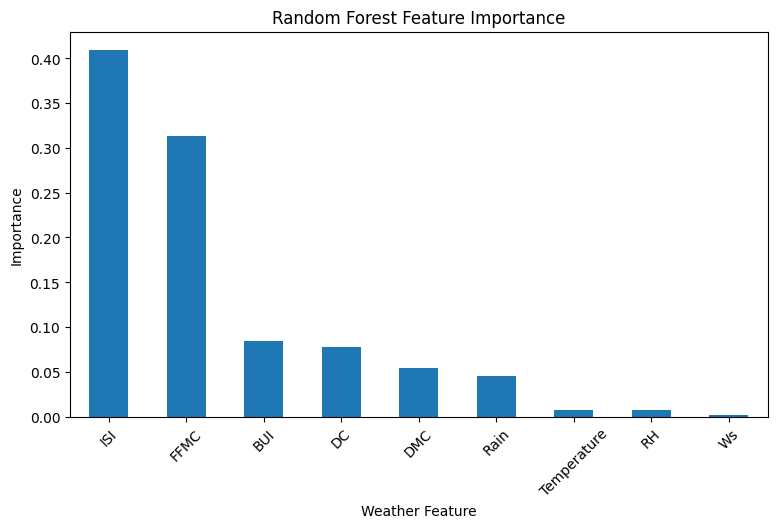

In [39]:

import pandas as pd

importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance)

importance.plot(
    kind="bar",
    title="Random Forest Feature Importance",
    ylabel="Importance",
    xlabel="Weather Feature",
    rot=45,
    figsize=(9, 5)
)


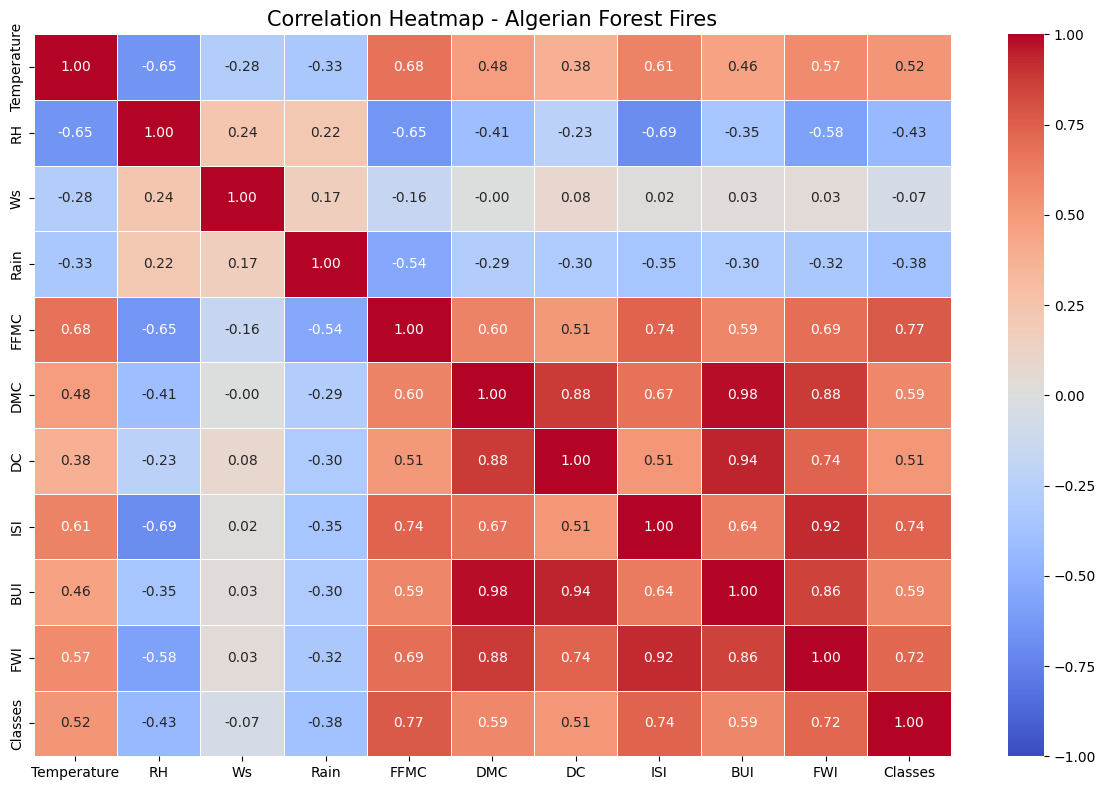

In [40]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical features and target
heatmap_cols = [
    "Temperature", "RH", "Ws", "Rain",
    "FFMC", "DMC", "DC", "ISI", "BUI", "FWI"
]

# Convert fire classes to numeric values
heatmap_df = df[heatmap_cols].copy()
heatmap_df["Classes"] = (
    df["Classes"].str.strip().str.lower()
    .map({"not fire": 0, "fire": 1})
)

# Calculate correlations
corr = heatmap_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap - Algerian Forest Fires", fontsize=15)
plt.tight_layout()
plt.show()


standardisation of featiure scaling

In [41]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [42]:
X_train_scaled

array([[ 0.78065654, -0.39408432, -0.49519708, ...,  2.4594505 ,
        -0.63283776,  0.95996061],
       [-1.13293838,  1.86036508, -0.13673352, ..., -0.73061755,
        -0.84422761, -0.66921722],
       [ 1.05402725,  0.60052571, -0.13673352, ...,  1.42842388,
         0.07179506,  1.70175647],
       ...,
       [ 1.05402725, -1.25607968,  0.22173004, ...,  1.86276229,
         1.57501176,  2.31876424],
       [ 0.78065654,  0.40160371,  0.22173004, ..., -0.68212346,
         0.02481954, -0.47510242],
       [ 1.87413936, -1.25607968, -1.21212419, ..., -0.38905045,
         1.1287443 , -0.02447876]])

BOX PLOT FOR THE STANDARDISATION

Text(0.5, 1.0, 'X_train After Scaling')

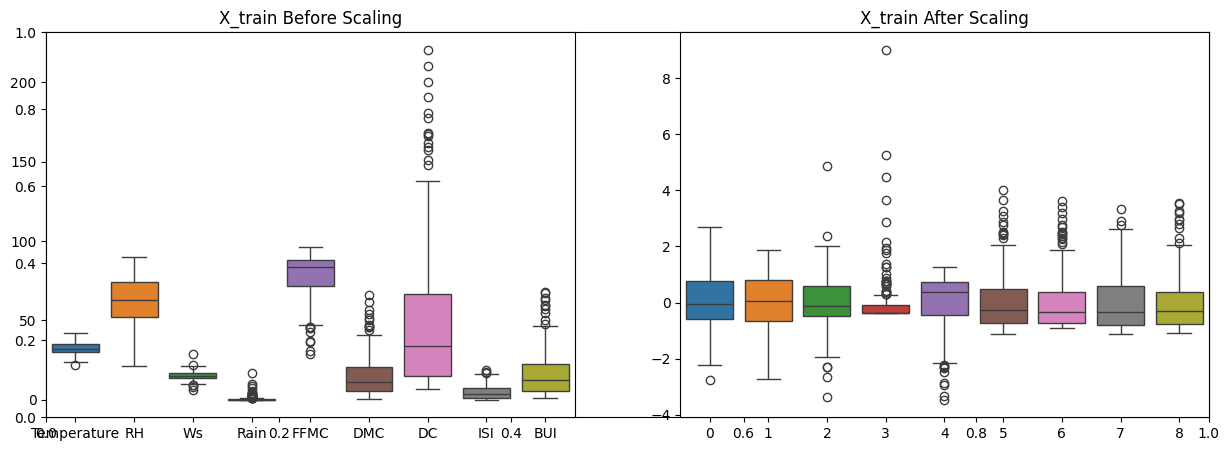

In [43]:
plt.subplots(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.boxplot(data=X_train)
plt.title('X_train Before Scaling')
plt.subplot(1, 2, 2)
sns.boxplot(data=X_train_scaled)
plt.title('X_train After Scaling')

linear reg model


Mean absolute error 0.234373417340082
R2 Score 0.6548236796314335


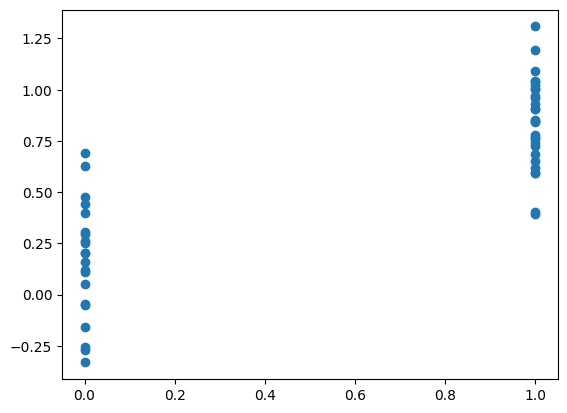

In [44]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
linreg=LinearRegression()
linreg.fit(X_train_scaled,y_train)
y_pred=linreg.predict(X_test_scaled)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean absolute error", mae)
print("R2 Score", score)
plt.scatter(y_test,y_pred)

In [45]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

reg_df = df.dropna(subset=[
    "FWI", "Temperature", "RH", "Ws", "Rain",
    "FFMC", "DMC", "DC", "ISI", "BUI"
]).copy()

features = [
    "Temperature", "RH", "Ws", "Rain",
    "FFMC", "DMC", "DC", "ISI", "BUI"
]

X_reg = reg_df[features]
y_reg = reg_df["FWI"]

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg,
    test_size=0.2,
    random_state=42
)

scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

print("Training data:", X_train_reg_scaled.shape)
print("Testing data:", X_test_reg_scaled.shape)


Training data: (194, 9)
Testing data: (49, 9)


In [46]:

from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_train_reg_scaled, y_train_reg)

print("Linear Regression training completed!")
print("Intercept:", lr_model.intercept_)
print("Coefficients:", lr_model.coef_)


Linear Regression training completed!
Intercept: 7.420103092783506
Coefficients: [-0.06817899 -0.07819109 -0.09428617  0.03138245 -0.71845377  0.1327554
 -0.31585419  5.24282804  3.95540463]


In [47]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred_reg = lr_model.predict(X_test_reg_scaled)

print("MAE:", round(mean_absolute_error(y_test_reg, y_pred_reg), 3))
print("MSE:", round(mean_squared_error(y_test_reg, y_pred_reg), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_reg, y_pred_reg)), 3))
print("R² Score:", round(r2_score(y_test_reg, y_pred_reg), 3))


MAE: 0.424
MSE: 0.355
RMSE: 0.596
R² Score: 0.988


LASSO REG


In [48]:

from sklearn.linear_model import Lasso

lasso_model = Lasso(alpha=0.1)

lasso_model.fit(X_train_reg_scaled, y_train_reg)

print("Lasso Regression training completed!")
print("Intercept:", lasso_model.intercept_)

print("\nFeature Coefficients:")
for feature, coef in zip(features, lasso_model.coef_):
    print(f"{feature}: {coef:.4f}")


Lasso Regression training completed!
Intercept: 7.420103092783506

Feature Coefficients:
Temperature: -0.0000
RH: -0.0000
Ws: 0.0000
Rain: 0.0000
FFMC: -0.2518
DMC: 1.0686
DC: 0.0000
ISI: 4.8807
BUI: 2.5712


In [49]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred_lasso = lasso_model.predict(X_test_reg_scaled)

print("MAE:", round(mean_absolute_error(y_test_reg, y_pred_lasso), 3))
print("MSE:", round(mean_squared_error(y_test_reg, y_pred_lasso), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_reg, y_pred_lasso)), 3))
print("R2 Score:", round(r2_score(y_test_reg, y_pred_lasso), 3))


MAE: 0.548
MSE: 0.538
RMSE: 0.733
R2 Score: 0.982


Compare Linear Regression vs. Lasso

In [50]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

models = {
    "Linear Regression": lr_model,
    "Lasso Regression": lasso_model
}

results = []

for name, reg_model in models.items():
    predictions = reg_model.predict(X_test_reg_scaled)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_reg, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, predictions)),
        "R2 Score": r2_score(y_test_reg, predictions)
    })

comparison = pd.DataFrame(results).round(3)
display(comparison)


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.424,0.596,0.988
1,Lasso Regression,0.548,0.733,0.982


let's check how Lasso is performing with different alpha values. A smaller alpha means weaker regularization.

In [51]:

from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import numpy as np
import pandas as pd

param_grid = {
    "alpha": [0.001, 0.01, 0.05, 0.1, 0.2, 0.5, 1.0]
}

grid = GridSearchCV(
    Lasso(max_iter=10000),
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error"
)

grid.fit(X_train_reg_scaled, y_train_reg)

best_lasso = grid.best_estimator_
predictions = best_lasso.predict(X_test_reg_scaled)

print("Best alpha:", grid.best_params_["alpha"])
print("Test MAE:", round(mean_absolute_error(y_test_reg, predictions), 3))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test_reg, predictions)), 3))
print("Test R2:", round(r2_score(y_test_reg, predictions), 3))


Best alpha: 0.05
Test MAE: 0.448
Test RMSE: 0.64
Test R2: 0.987


Ridge Regression L2

RIDGE REGRESSION RESULTS
-----------------------------------
Best alpha: 5
MAE:  0.569
MSE:  0.753
RMSE: 0.868
R2 Score: 0.975


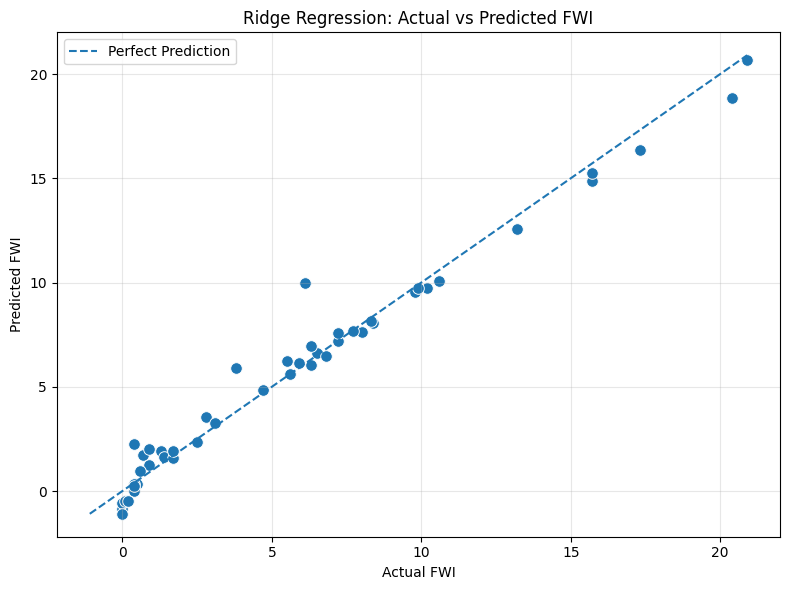

In [52]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Tune Ridge alpha using training data only
param_grid = {
    "alpha": [0.001, 0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100]
}

ridge_grid = GridSearchCV(
    Ridge(),
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error"
)

ridge_grid.fit(X_train_reg_scaled, y_train_reg)

# Best Ridge model
best_ridge = ridge_grid.best_estimator_
y_pred_ridge = best_ridge.predict(X_test_reg_scaled)

# Evaluation
mae = mean_absolute_error(y_test_reg, y_pred_ridge)
mse = mean_squared_error(y_test_reg, y_pred_ridge)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_ridge)

print("RIDGE REGRESSION RESULTS")
print("-" * 35)
print("Best alpha:", ridge_grid.best_params_["alpha"])
print(f"MAE:  {mae:.3f}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2 Score: {r2:.3f}")

# Actual vs Predicted scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test_reg, y=y_pred_ridge, s=70)

min_val = min(y_test_reg.min(), y_pred_ridge.min())
max_val = max(y_test_reg.max(), y_pred_ridge.max())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual FWI")
plt.ylabel("Predicted FWI")
plt.title("Ridge Regression: Actual vs Predicted FWI")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


ElasticNet combines L1 regularization (Lasso) and L2 regularization (Ridge).

ELASTICNET REGRESSION RESULTS
----------------------------------------
Best parameters: {'alpha': 0.05, 'l1_ratio': 0.7}
MAE:  0.525
MSE:  0.646
RMSE: 0.804
R2 Score: 0.979


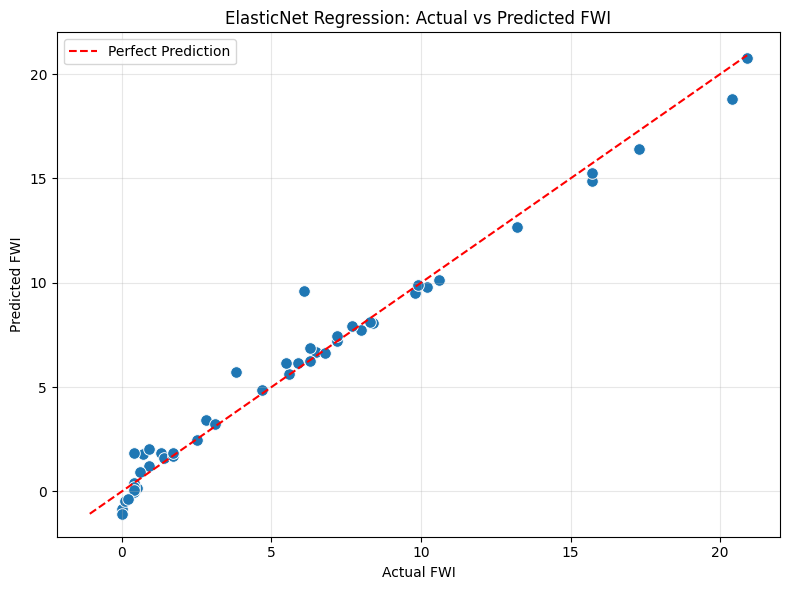

In [53]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import ElasticNet
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Tune ElasticNet using training data only
param_grid = {
    "alpha": [0.001, 0.01, 0.05, 0.1, 0.5, 1, 5],
    "l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
}

elastic_grid = GridSearchCV(
    ElasticNet(max_iter=20000),
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error"
)

elastic_grid.fit(X_train_reg_scaled, y_train_reg)

# Best model and predictions
best_elastic = elastic_grid.best_estimator_
y_pred_elastic = best_elastic.predict(X_test_reg_scaled)

# Evaluation metrics
mae = mean_absolute_error(y_test_reg, y_pred_elastic)
mse = mean_squared_error(y_test_reg, y_pred_elastic)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_elastic)

print("ELASTICNET REGRESSION RESULTS")
print("-" * 40)
print("Best parameters:", elastic_grid.best_params_)
print(f"MAE:  {mae:.3f}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2 Score: {r2:.3f}")

# Actual vs Predicted scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test_reg, y=y_pred_elastic, s=70)

min_val = min(y_test_reg.min(), y_pred_elastic.min())
max_val = max(y_test_reg.max(), y_pred_elastic.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual FWI")
plt.ylabel("Predicted FWI")
plt.title("ElasticNet Regression: Actual vs Predicted FWI")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


LASSOCV

Best Alpha: 0.04391

LASSOCV RESULTS
------------------------------
MAE:  0.440
MSE:  0.397
RMSE: 0.630
R2 Score: 0.987


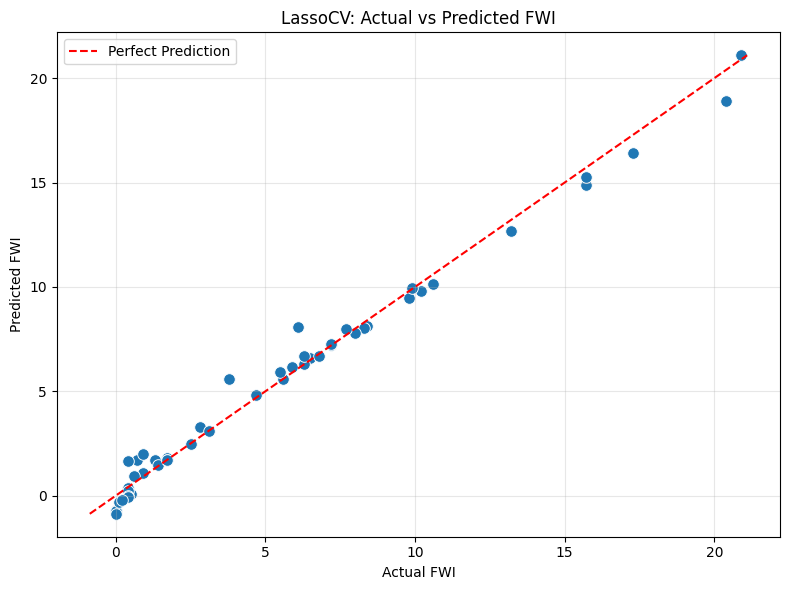


Feature Coefficients:
Temperature: -0.0000
RH: -0.0000
Ws: -0.0000
Rain: 0.0066
FFMC: -0.4990
DMC: 0.9533
DC: 0.0000
ISI: 5.0811
BUI: 2.7628


In [54]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Train LassoCV with 5-fold cross-validation
lasso_cv = LassoCV(
    cv=5,
    max_iter=20000,
    random_state=42
)

lasso_cv.fit(X_train_reg_scaled, y_train_reg)

# Best alpha selected by cross-validation
print("Best Alpha:", round(lasso_cv.alpha_, 5))

# Predict on test data
y_pred_lasso_cv = lasso_cv.predict(X_test_reg_scaled)

# Evaluate the model
mae = mean_absolute_error(y_test_reg, y_pred_lasso_cv)
mse = mean_squared_error(y_test_reg, y_pred_lasso_cv)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_lasso_cv)

print("\nLASSOCV RESULTS")
print("-" * 30)
print(f"MAE:  {mae:.3f}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2 Score: {r2:.3f}")

# Plot actual vs predicted FWI
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test_reg, y=y_pred_lasso_cv, s=70)

min_val = min(y_test_reg.min(), y_pred_lasso_cv.min())
max_val = max(y_test_reg.max(), y_pred_lasso_cv.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual FWI")
plt.ylabel("Predicted FWI")
plt.title("LassoCV: Actual vs Predicted FWI")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Show feature coefficients
print("\nFeature Coefficients:")
for feature, coef in zip(features, lasso_cv.coef_):
    print(f"{feature}: {coef:.4f}")


In [56]:
lasso_cv.alphas_

array([7.1563667 , 6.67405153, 6.2242428 , 5.80474966, 5.41352896,
       5.04867523, 4.70841142, 4.39108025, 4.09513613, 3.81913766,
       3.56174057, 3.32169117, 3.09782031, 2.88903759, 2.69432612,
       2.51273756, 2.34338746, 2.18545099, 2.0381589 , 1.90079382,
       1.77268667, 1.65321353, 1.54179247, 1.43788081, 1.34097246,
       1.2505954 , 1.16630946, 1.08770411, 1.01439649, 0.94602956,
       0.88227033, 0.82280827, 0.76735374, 0.71563667, 0.66740515,
       0.62242428, 0.58047497, 0.5413529 , 0.50486752, 0.47084114,
       0.43910802, 0.40951361, 0.38191377, 0.35617406, 0.33216912,
       0.30978203, 0.28890376, 0.26943261, 0.25127376, 0.23433875,
       0.2185451 , 0.20381589, 0.19007938, 0.17726867, 0.16532135,
       0.15417925, 0.14378808, 0.13409725, 0.12505954, 0.11663095,
       0.10877041, 0.10143965, 0.09460296, 0.08822703, 0.08228083,
       0.07673537, 0.07156367, 0.06674052, 0.06224243, 0.0580475 ,
       0.05413529, 0.05048675, 0.04708411, 0.0439108 , 0.04095

compare all model and save

In [57]:

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Models already trained in your notebook
models = {
    "Linear Regression": globals().get("lr_model"),
    "Lasso": globals().get("lasso_model"),
    "Tuned Lasso": globals().get("best_lasso"),
    "LassoCV": globals().get("lasso_cv"),
    "Ridge": globals().get("best_ridge", globals().get("ridge_model")),
    "ElasticNet": globals().get("best_elastic")
}

results = []
available_models = {}

for name, model in models.items():
    if model is None:
        print(f"Skipping {name}: model not found.")
        continue

    predictions = model.predict(X_test_reg_scaled)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_reg, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, predictions)),
        "R2 Score": r2_score(y_test_reg, predictions)
    })

    available_models[name] = model

if not results:
    raise ValueError("No trained regression models found.")

# Compare models: lower RMSE is better
comparison = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("\nREGRESSION MODEL COMPARISON")
display(comparison.round(4))

# Save comparison table
comparison.to_csv("regression_model_comparison.csv", index=False)
comparison.to_excel("regression_model_comparison.xlsx", index=False)

# Save trained estimators
os.makedirs("saved_regression_models", exist_ok=True)

for name, model in available_models.items():
    filename = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "_")
        + ".joblib"
    )
    joblib.dump(
        model,
        os.path.join("saved_regression_models", filename)
    )

# Save scaler and feature names used by these models
joblib.dump(scaler_reg, "regression_scaler.joblib")
joblib.dump(features, "regression_features.joblib")

print("\nSaved comparison CSV and Excel files.")
print("Saved trained models in saved_regression_models/")
print("Saved regression scaler and feature names.")

print("\nBest model by test RMSE:", comparison.iloc[0]["Model"])
print("Test RMSE:", round(comparison.iloc[0]["RMSE"], 4))



REGRESSION MODEL COMPARISON


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.4240,0.5962,0.9883
1,LassoCV,0.4398,0.6302,0.9869
2,Tuned Lasso,0.4483,0.6395,0.9865
3,Lasso,0.5481,0.7332,0.9823
4,ElasticNet,0.5253,0.8037,0.9787
5,Ridge,0.5685,0.8677,0.9752



Saved comparison CSV and Excel files.
Saved trained models in saved_regression_models/
Saved regression scaler and feature names.

Best model by test RMSE: Linear Regression
Test RMSE: 0.5962


In [58]:

import shutil
from google.colab import files

shutil.make_archive(
    "saved_regression_models",
    "zip",
    "saved_regression_models"
)

files.download("regression_model_comparison.csv")
files.download("regression_model_comparison.xlsx")
files.download("saved_regression_models.zip")
files.download("regression_scaler.joblib")
files.download("regression_features.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

FINAL PIPELINE


In [59]:

import os
import shutil
import joblib
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create a folder for the complete project
save_dir = "FWI_Regression_Project"
os.makedirs(save_dir, exist_ok=True)

# 1. Save all trained regression models
for name, model in available_models.items():
    filename = name.lower().replace(" ", "_").replace("-", "_") + ".joblib"
    joblib.dump(model, os.path.join(save_dir, filename))

# 2. Build and save the final pipeline using unscaled training data
final_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

final_pipeline.fit(X_train_reg, y_train_reg)
joblib.dump(final_pipeline, os.path.join(save_dir, "best_fwi_pipeline.joblib"))

# 3. Evaluate the saved pipeline on the original test features
final_predictions = final_pipeline.predict(X_test_reg)

final_metrics = pd.DataFrame([{
    "Model": "Linear Regression Pipeline",
    "MAE": mean_absolute_error(y_test_reg, final_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test_reg, final_predictions)),
    "R2 Score": r2_score(y_test_reg, final_predictions)
}])

final_metrics.to_csv(
    os.path.join(save_dir, "final_model_metrics.csv"), index=False
)

# 4. Save model comparison in CSV and Excel
comparison.to_csv(
    os.path.join(save_dir, "regression_model_comparison.csv"), index=False
)
comparison.to_excel(
    os.path.join(save_dir, "regression_model_comparison.xlsx"), index=False
)

# 5. Save actual versus predicted test results
predictions_df = pd.DataFrame({
    "Actual_FWI": np.asarray(y_test_reg),
    "Predicted_FWI": final_predictions,
    "Residual": np.asarray(y_test_reg) - final_predictions
})
predictions_df.to_csv(
    os.path.join(save_dir, "test_predictions.csv"), index=False
)

# 6. Save feature names and original scaler
joblib.dump(features, os.path.join(save_dir, "feature_names.joblib"))
joblib.dump(scaler_reg, os.path.join(save_dir, "original_regression_scaler.joblib"))

# 7. Package everything into one ZIP
zip_path = shutil.make_archive(save_dir, "zip", save_dir)

print("FINAL PIPELINE METRICS")
display(final_metrics.round(4))

print("\nSaved project ZIP:", zip_path)
print("Files included:")
for filename in sorted(os.listdir(save_dir)):
    print("-", filename)

# Download the complete project
from google.colab import files
files.download(zip_path)


FINAL PIPELINE METRICS


,Model,MAE,RMSE,R2 Score
0,Linear Regression Pipeline,0.424,0.5962,0.9883



Saved project ZIP: /content/FWI_Regression_Project.zip
Files included:
- best_fwi_pipeline.joblib
- elasticnet.joblib
- feature_names.joblib
- final_model_metrics.csv
- lasso.joblib
- lassocv.joblib
- linear_regression.joblib
- original_regression_scaler.joblib
- regression_model_comparison.csv
- regression_model_comparison.xlsx
- ridge.joblib
- test_predictions.csv
- tuned_lasso.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>